# Implementing Leap Frog method to solve an IVP


## 1. Objective

The objective of this assignment is to implement the Leapfrog method to solve the equations governing electron plasma oscillations. The numerical solution is compared with the analytical solution to verify the accuracy of the method.

## 2. Governing Equations

The motion of an electron undergoing plasma oscillations is described by the following differential equations:

$$
\frac{dx}{dt}=v
$$

$$
\frac{dv}{dt}=a(x)=-\omega_p^2x
$$

where $x$ represents the position, $v$ represents the velocity, $a(x)$ is the acceleration, and $\omega_p$ is the plasma frequency.

Combining these equations gives the second-order differential equation:

$$
\frac{d^2x}{dt^2}+\omega_p^2x=0
$$

For this assignment, the plasma frequency and initial conditions are:

$$
\omega_p=1,\qquad x(0)=0.5,\qquad v(0)=0
$$

The analytical solutions for position and velocity are:

$$
x(t)=0.5\cos(\omega_pt)
$$

$$
v(t)=-0.5\omega_p\sin(\omega_pt)
$$

For $\omega_p=1$, these simplify to:

$$
x(t)=0.5\cos t,\qquad v(t)=-0.5\sin t
$$

These analytical solutions are used as reference solutions for comparison with the numerical results.

## 3. Leapfrog Method

The Leapfrog method is a numerical integration technique in which position and velocity are evaluated at staggered time levels. Position is evaluated at integer time steps, while velocity is evaluated at half-time steps.

The time levels are defined as:

$$
t_n=nh,\qquad t_{n+\frac12}=\left(n+\frac12\right)h
$$

where $h$ is the time-step size.

### 3.1. Velocity Update

Using the acceleration equation, the velocity at the next half-time step is calculated as:

$$
v_{n+\frac12}=v_{n-\frac12}+a(x_n)h
$$

Substituting $a(x_n)=-\omega_p^2x_n$ gives:

$$
\boxed{v_{n+\frac12}=v_{n-\frac12}-\omega_p^2x_nh}
$$

### 3.2. Position Update

The position at the next whole-time step is calculated using the updated velocity:

$$
x_{n+1}=x_n+v_{n+\frac12}h
$$

Therefore, the position update equation is:

$$
\boxed{x_{n+1}=x_n+v_{n+\frac12}h}
$$

These two equations are applied successively to calculate the position and velocity at each time step.

### 3.3. Initialisation of Half-Step Velocity

The Leapfrog method requires the initial velocity at the half-time step, $v_{-\frac12}$, whereas the given initial condition specifies the velocity at $t=0$, denoted by $v_0$.

The half-step velocity is initialised using:

$$
v_{-\frac12}=v_0-\frac{h}{2}a(x_0)
$$

Since $a(x_0)=-\omega_p^2x_0$, we obtain:

$$
\boxed{v_{-\frac12}=v_0+\frac{h}{2}\omega_p^2x_0}
$$


## 4. Numerical Integration and Verification

The Leapfrog method is implemented using the velocity and position update equations. The integration is performed over the time interval:

$$
0\leq t\leq20
$$

with a time-step size of:

$$
h=0.1
$$

The total number of time steps is:

$$
N=\frac{t_{\mathrm{final}}}{h}
$$

At each iteration, the velocity is updated first, followed by the position. The resulting numerical solution is compared with the analytical solution to evaluate its accuracy.

The following plots are generated:

1. **Position versus time:** The numerical position is compared with $x(t)=0.5\cos t$.
2. **Velocity versus time:** The numerical half-step velocity is compared with the analytical velocity $v(t)=-0.5\sin t$ at the corresponding half-time levels.
3. **Phase-space trajectory:** Position is plotted against velocity to examine the oscillatory motion of the electron.




# Task 1: Implementing the Leapfrog function

The very first task is to create a leapfrog function. The input parameters has been taken as x, v and h which are position, half time velocity and step-size of the electron particle respectively

1. So inside the function we'll define the value of plasma frequncy wp as 1 as stated in the assignment
2. Then we would defined the acceleration as given by the formula as $$ a(x)=-\omega_p^2x $$
3. Then using the formula for velocity using acceleration is given by $$ v_{n+\frac12}=v_{n \frac12}+a(x_n)h $$
4. Then again defining the position using velocity as given by the formula $$x_{n+1} = x_n + v_{n+\frac{1}{2}}h$$
5. Now finally we're returning the values of position (x) and velocity (v) 

In [2]:
import numpy as np
import matplotlib.pyplot as plt
#Defining a leapfrog function which intakes three parameters x, v and h, which are position, half time velocity and step-size respectively
def leapfrog(x, v, h):
    wp=1                #initializing the value of plasma frequency to 1 as stated in the assignemnt
    accln= -(wp**2)*x
    v= v + (accln*h)
    x= x + (v*h)
    return x,v


# Task 2: Initializing the half-step by computing the staggered velocity

Now in the problem we are given the initial velocity and initial postion, but what we actually need for our formula is the half-step velocity. Hence I have implement these logical steps to calculate it.

1. Firstly, we have initiated the values of position (x), velocity (v) and the time step (h) as stated in the assignment. x= 0.5, v=0.05 and h=0.1
2. Now, we have the position at the initial time but we have only velocity not hte half-time step velocity. Hence we're using the following formula and evaluating the same $$v_{\text{half}} = v_0 - \frac{h}{2}a(x_0)$$
3. Now, just to check whether our devised function works, we'll be calling the function leapfrog once and print the values we've got.

In [3]:
#Now for the task 2, we'll define the initial values for our problem which are already listed in assignment
x=0.5
v=0.0
h=0.1
wp=1

#now initialize the half-step velocity
v= v - (h/2)* (-x)

#Now, we'll call the funtion
x_new, v_new= leapfrog(x,v,h)
print(x_new, v_new)

0.4975 -0.025


# Task 3: Plotting the Space-phase trajectory 

Now, in this step we are majorly creating a an array for time of position and half-time step velocity and then we will calculate their values at the time intended and then we'll finally store it in an array. A thorough explanation is given using the steps followed.

1. We'll first define the last limit till when we want our time step to last
2. Next, creating a array of values times for position and half-step time velocity using "arange" function in numpy
3. similary, using "zeros" numpy function we'll create an arrray for storing the values of position and half-step time velocities (Now, initially the array will be of zeros but we'll be inserting the values in it in next steps)
4. Now, we'll initialise the array by assigning the initial values (we had defined in the code) to the entity at index "0", which is the starting point for any array
5. Now, we're calling our leapfrog function and storing the values of position and half-step time velocities in the array we had defined earlier. We'll run this in multiple loops till we reach the N that we had defined earlier
6. Now, in next step we will define the exact solutions by using their mathematical formulas $x(t) = 0.5\cos(t)$ for position and $v(t) = -0.5\sin(t)$ for time, respectively

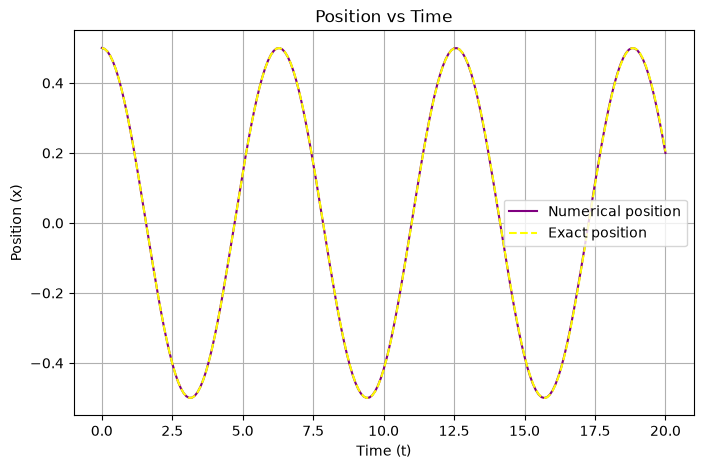

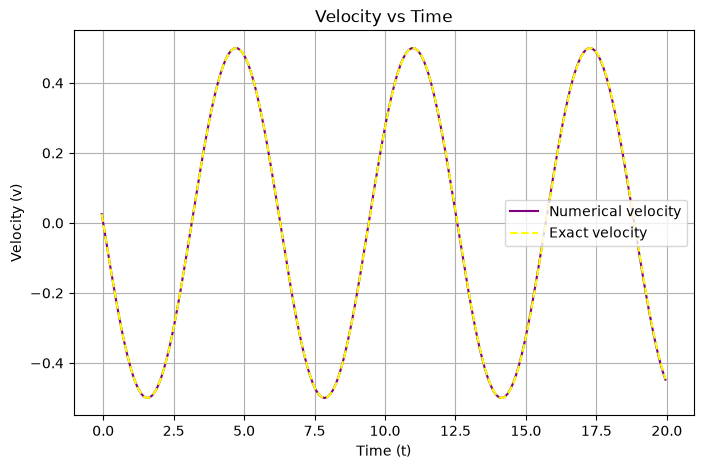

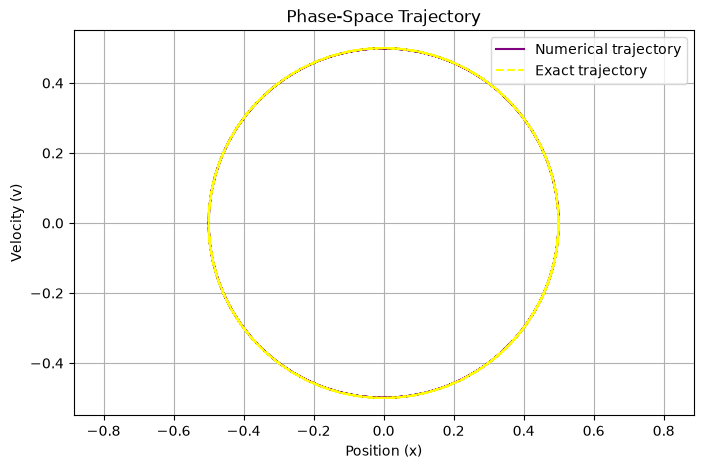

In [4]:
t_final = 20.0

# Now, we'll define the number of time steps using the variable N
N = int(t_final / h)

# Now, we'll create the time arrays for position and velocity
t_values = np.arange(N + 1) * h
t_half = (np.arange(N + 1) - 0.5) * h

# Now, we'll need to store the values of position and velocity at t_values and t_half respectively, hence we'll create the array using np.zeros
x_values = np.zeros(N + 1)
v_values = np.zeros(N + 1)

# Now, we'll store the initial values as we had stated earlier in the code after we defined the function
x_values[0] = x
v_values[0] = v

# Now we'll integrate all time steps usin the leapfrog function we created earlier
for n in range(N):
    x_values[n + 1], v_values[n + 1] = leapfrog(
        x_values[n], v_values[n], h
    )

# We'll also calculate the exact values of both x and v as the given function is a differential function
x_exact = 0.5 * np.cos(t_values)
v_exact = -0.5 * np.sin(t_half)

# Now plotting for position vs time
plt.figure(figsize=(8, 5))
plt.plot(t_values, x_values, label="Numerical position", color='purple')
plt.plot(t_values, x_exact, "--", label="Exact position", color= 'yellow')
plt.xlabel("Time (t)")
plt.ylabel("Position (x)")
plt.title("Position vs Time")
plt.legend()
plt.grid(True)
plt.show()

# Now plotting the velocity vs time graph
plt.figure(figsize=(8, 5))
plt.plot(t_half, v_values, label="Numerical velocity", color='purple')
plt.plot(t_half, v_exact, "--", label="Exact velocity", color='yellow')
plt.xlabel("Time (t)")
plt.ylabel("Velocity (v)")
plt.title("Velocity vs Time")
plt.legend()
plt.grid(True)
plt.show()

# Plot 3: Phase-space trajectory
v_centered = 0.5 * (v_values[:-1] + v_values[1:])

plt.figure(figsize=(8, 5))
plt.plot(x_values[:-1], v_centered, label="Numerical trajectory", color='purple')
plt.plot(
    x_exact[:-1],
    -0.5 * np.sin(t_values[:-1]),
    "--",
    label="Exact trajectory", color='yellow'
)
plt.xlabel("Position (x)")
plt.ylabel("Velocity (v)")
plt.title("Phase-Space Trajectory")
plt.legend()
plt.grid(True)
plt.axis("equal")
plt.show()


# Task 4: Plot Convergence (Plotting the error variation with time step variation)

Now the brief idea for this section is to find the error behavior with increasing the time-step  (increasing means reducing the step size so that more number of iterations are performed). We'll also find by what order the error is getting reduced

1. Now, the very first thing we'll do is to define an array with four different time-steps as per given in the assignment
2. Then we'll form an array which will later be used for storing the  error values
3. Then, stating the initial condition (For my convenience here, to understand the code)
4. Then we'll be running a nested loop. The outer loop takes in 4 values of h as defined in each operation of loop. i.e the outer loop will be used for 4 total times. The inner loop calculates the error values and stores it in the initial error arrays that we have created.
5. Now, we'll plot 2 main plots here, first one with position error v/s time step and second one with velocity error v/s time step.
6. Then we'll proceed with the operation of finding the order of the convergence for both staggered and unstaggered state

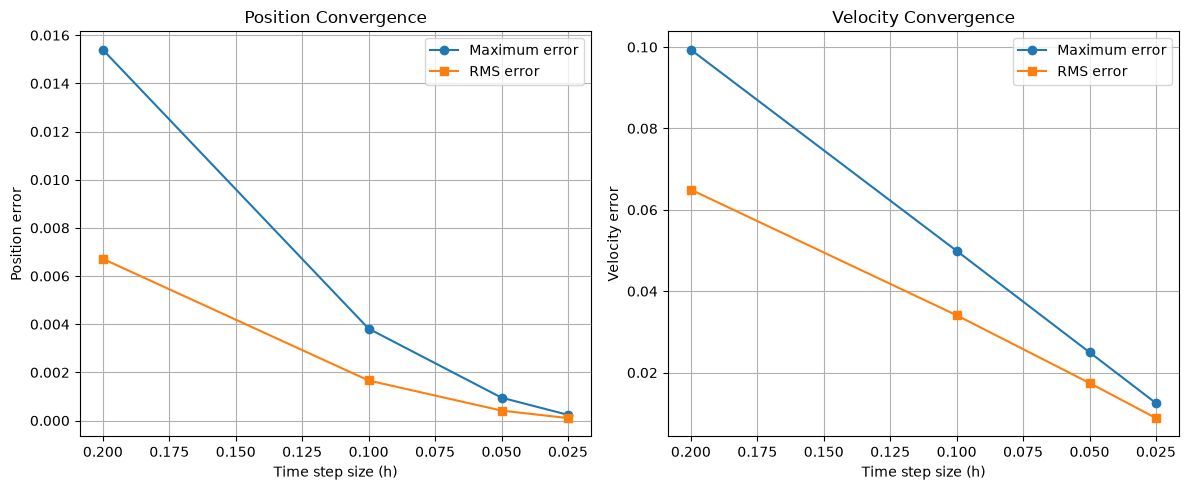

Maximum position errors: [np.float64(0.00023779054510253417), np.float64(0.0009516945580628489), np.float64(0.0038152808690173623), np.float64(0.015396153502616333)]


In [20]:
#Firstly, storing the 4 different time-steps which we'll be using for our analysis in form of array
h = np.array([0.025, 0.05, 0.1, 0.2])

#Now we'll store the erros in position (x), velocity (v) in form of arrays
error_x = []
error_v = []
error_rms_x = []
error_rms_v = []

# Stating the inital conditions again 
x0 = 0.5
v0 = 0
Wp = 1

# Nested loops for calulating the x and v for each of the h values (which we are taking as 4 different values)
for i in range(len(h)):
    h_new = h[i]
    n = int(20 / h_new)

    x = x0
    
    # Calculating initial half-step velocity
    a0 = -(Wp**2) * x0
    v = v0 - 0.5 * h_new * a0

    p_new = [x]
    v_half = [v]

    # initiating the leapfrog function for these each values of h
    for j in range(n):
        x, v = leapfrog(x, v, h_new)
        p_new.append(x)
        v_half.append(v)

    p_new = np.array(p_new)
    v_half = np.array(v_half)

    # Storing the time in an array
    time = np.arange(n + 1) * h_new

    # Calculating velocity at full time steps
    q_new = np.zeros(n + 1)
    q_new[0] = v0
    q_new[1:] = 0.5 * (v_half[:-1] + v_half[1:])

    # Finding exact solutions
    x_exact = 0.5 * np.cos(time)
    v_exact = -0.5 * np.sin(time)

    # Now, we'll calculate our errors
    x_diff = x_exact - p_new
    v_diff = v_exact - q_new

    error_x.append(np.max(np.abs(x_diff)))
    error_v.append(np.max(np.abs(v_diff)))

    error_rms_x.append(np.sqrt(np.mean(x_diff**2)))
    error_rms_v.append(np.sqrt(np.mean(v_diff**2)))
    
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(h, error_x, 'o-', label='Maximum error')
plt.plot(h, error_rms_x, 's-', label='RMS error')
plt.gca().invert_xaxis()
plt.xlabel('Time step size (h)')
plt.ylabel('Position error')
plt.title('Position Convergence')
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(h, error_v, 'o-', label='Maximum error')
plt.plot(h, error_rms_v, 's-', label='RMS error')
plt.gca().invert_xaxis()
plt.xlabel('Time step size (h)')
plt.ylabel('Velocity error')
plt.title('Velocity Convergence')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()


# Now, we'll print the maximum position errors we've got for each value of h
print("Maximum position errors:", error_x)

In [19]:
# Staggered P values

order = []

#Writing a loop for calculating  the error ratio which compares the next one with previous one
for i in range(1, len(error_x)):
    error_ratio = error_x[i] / error_x[i-1]
    order.append(int(np.log2(error_ratio)))

print(f"order_staggered={order}")


## Unstaggered

h = np.array([0.025, 0.05, 0.1, 0.2])
w = len(h)

error_x_us = []
error_v_us = []
error_rms_x_us = []
error_rms_v_us = []

for i in range(0, w):
    t = 20
    h_new = h[i]
    n = int(t / h_new)

    x = 0.5
    vi = 0
    Wp = 1
    a = -(Wp)**2 * x
    v = vi

    p_new = []
    q_new = []

    p_new.append(x)
    q_new.append(vi)

    t = np.arange(0, 20 + h_new, h_new)

    x_exact = 0.5 * np.cos(t)
    v_exact = -0.5 * np.sin(t)

    for j in range(0, n):
        s_new = leapfrog(x, v, h_new)

        p_new.append(s_new[0])
        q_new.append(s_new[1])

        x = s_new[0]
        v = s_new[1]

    #Now calculating for the error
    x_diff = x_exact - p_new
    v_diff = v_exact - q_new

    max_error_x_us = np.max(abs(x_diff))
    rms_error_x_us = np.sqrt(np.mean(x_diff**2))

    max_error_v_us = np.max(abs(v_diff))
    rms_error_v_us = np.sqrt(np.mean(v_diff**2))

    error_x_us.append(max_error_x_us)
    error_v_us.append(max_error_v_us)
    error_rms_x_us.append(rms_error_x_us)
    error_rms_v_us.append(rms_error_v_us)


# Unstaggered P values

order_us = []

for i in range(1, len(error_x_us)):
    error_ratio = error_x_us[i] / error_x_us[i-1]
    order_us.append(int(np.log2(error_ratio)))

print(f"order_unstaggered={order_us}")


order_staggered=[2, 2, 2]
order_unstaggered=[1, 1, 1]
